# Aprendizaje Automático Avanzado — Unidad 3
## Aprendizaje No Supervisado y Modelos Generativos

**Maestría en Inteligencia Artificial · TecNM Virtual**

Este cuaderno de prácticas acompaña la teoría de la Unidad 3. Contiene ejemplos **ejecutables** que ilustran los conceptos principales del tema, utilizando los conjuntos de datos de la asignatura.

> **Requisitos:** `pip install scikit-learn pandas numpy matplotlib`
> Coloca los archivos `.csv` de la carpeta *Recursos y materiales* junto a este cuaderno (o ajusta la ruta `DATA`).

---
### Contenido de la práctica
1. Agrupamiento con **K-Means** y selección de *k*
2. Reducción de dimensionalidad con **PCA**
3. Detección de anomalías
4. Idea de un modelo **generativo** simple (muestreo gaussiano)


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
DATA = Path('.') if Path('breast_cancer_dataset.csv').exists() else Path('data')
df = pd.read_csv(DATA/'breast_cancer_dataset.csv')
X = StandardScaler().fit_transform(df.drop(columns=['diagnosis']))
print('Datos escalados:', X.shape)

Datos escalados: (569, 30)


### 1. K-Means y el método del codo
Elegimos el número de grupos *k* observando dónde la inercia deja de disminuir marcadamente.

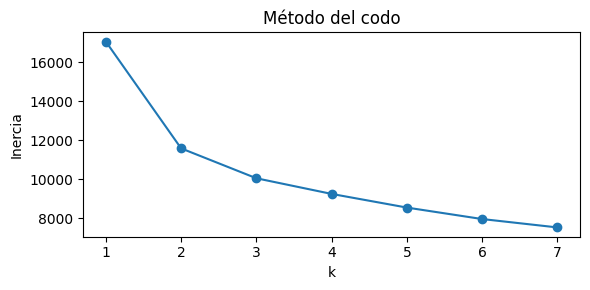

In [2]:
from sklearn.cluster import KMeans
inercias = []
for k in range(1,8):
    inercias.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_)
plt.figure(figsize=(6,3))
plt.plot(range(1,8), inercias, 'o-'); plt.xlabel('k'); plt.ylabel('Inercia')
plt.title('Método del codo'); plt.tight_layout(); plt.show()

### 2. PCA para visualización

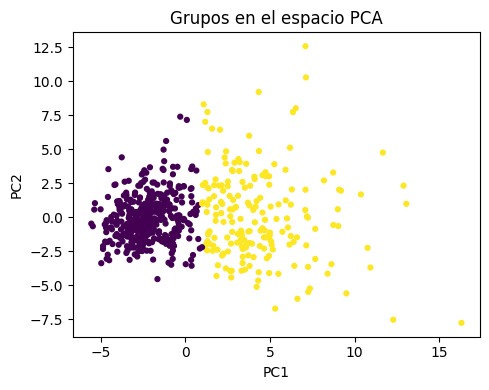

In [3]:
from sklearn.decomposition import PCA
Z = PCA(n_components=2).fit_transform(X)
labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)
plt.figure(figsize=(5,4))
plt.scatter(Z[:,0], Z[:,1], c=labels, cmap='viridis', s=12)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Grupos en el espacio PCA')
plt.tight_layout(); plt.show()

### 3. Detección de anomalías
Las muestras alejadas del centro de su grupo pueden considerarse **atípicas**.

In [4]:
from numpy.linalg import norm
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X)
dist = norm(X - km.cluster_centers_[km.labels_], axis=1)
umbral = np.percentile(dist, 95)
print('Muestras atípicas (5% más lejanas):', int((dist>umbral).sum()))

Muestras atípicas (5% más lejanas): 29


### 4. Modelo generativo simple
Un modelo generativo aprende la distribución de los datos para **crear muestras nuevas**. Aquí ajustamos una gaussiana multivariante y generamos datos sintéticos.

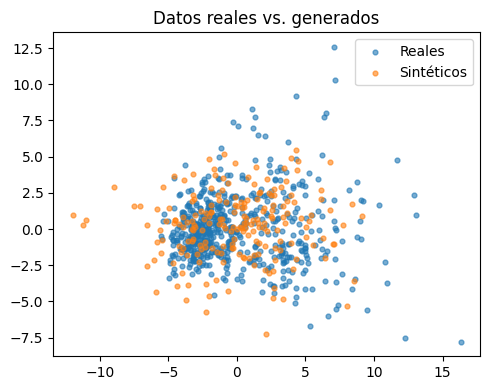

In [5]:
mu = X.mean(axis=0); cov = np.cov(X, rowvar=False)
sinteticos = np.random.multivariate_normal(mu, cov, size=200)
Z2 = PCA(n_components=2).fit(X)
plt.figure(figsize=(5,4))
plt.scatter(Z2.transform(X)[:,0], Z2.transform(X)[:,1], s=12, label='Reales', alpha=0.6)
plt.scatter(Z2.transform(sinteticos)[:,0], Z2.transform(sinteticos)[:,1], s=12, label='Sintéticos', alpha=0.6)
plt.legend(); plt.title('Datos reales vs. generados'); plt.tight_layout(); plt.show()

---
### Ejercicio propuesto
1. Prueba `DBSCAN` en lugar de K-Means: ¿detecta ruido automáticamente?
2. Compara los histogramas de una variable real vs. su versión sintética.
3. Investiga los **autoencoders** y las **GAN** como modelos generativos profundos.